# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

    def _mostrar_heap(self):
        """Dibuja el estado actual del heap como un árbol binario."""
        import math
        import matplotlib.pyplot as plt
        from matplotlib.patches import Circle

        n = len(self.arreglo) - 1

        if n == 0:
            fig, ax = plt.subplots(figsize=(4, 2))
            ax.text(0.5, 0.5, "Heap vacío", ha="center", va="center")
            ax.axis("off")
            plt.show()
            return

        profundidad = math.floor(math.log2(n))
        ancho = max(6, 1.15 * (2 ** profundidad))
        alto = max(2.5, 1.35 * (profundidad + 1))

        fig, ax = plt.subplots(figsize=(ancho, alto))
        posiciones = {}

        # Calcula la posición de cada nodo según su índice en el arreglo.
        for i in range(1, n + 1):
            nivel = i.bit_length() - 1
            primer_indice = 2 ** nivel
            posicion_nivel = i - primer_indice

            x = (posicion_nivel + 0.5) / (2 ** nivel)
            y = -nivel
            posiciones[i] = (x, y)

        # Dibuja primero las aristas para que queden detrás de los nodos.
        for i in range(1, n + 1):
            for hijo in (2 * i, 2 * i + 1):
                if hijo <= n:
                    x1, y1 = posiciones[i]
                    x2, y2 = posiciones[hijo]
                    ax.plot([x1, x2], [y1, y2],
                            color="black", linewidth=1.5, zorder=1)

        radio = 0.22 / (2 ** max(0, profundidad - 2))
        radio = max(0.055, radio)

        # Dibuja los nodos y escribe su valor.
        for i, (x, y) in posiciones.items():
            nodo = Circle(
                (x, y), radio,
                facecolor="#E8F1FA",
                edgecolor="#24527A",
                linewidth=1.5,
                zorder=2
            )
            ax.add_patch(nodo)
            ax.text(
                x, y, str(self.arreglo[i]),
                ha="center", va="center",
                fontsize=max(7, 12 - profundidad),
                zorder=3
            )

        ax.set_xlim(-0.08, 1.08)
        ax.set_ylim(-profundidad - 0.6, 0.6)
        ax.set_aspect("equal")
        ax.axis("off")
        plt.tight_layout()
        plt.show()

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        indice_hijo = len(self.arreglo) - 1

        # Sube el nuevo elemento mientras sea menor que su padre.
        while indice_hijo > 1:
            indice_padre = indice_hijo // 2

            if self.arreglo[indice_hijo] >= self.arreglo[indice_padre]:
                break

            self.arreglo[indice_hijo], self.arreglo[indice_padre] = (
                self.arreglo[indice_padre], self.arreglo[indice_hijo]
            )
            indice_hijo = indice_padre

        if imagen:
            self._mostrar_heap()

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) == 1:
            raise IndexError("No se puede eliminar de un heap vacío.")

        menor = self.arreglo[1]
        ultimo = self.arreglo.pop()

        if len(self.arreglo) > 1:
            self.arreglo[1] = ultimo
            indice = 1

            # Baja el elemento hasta recuperar la propiedad de min heap.
            while 2 * indice < len(self.arreglo):
                hijo = 2 * indice
                hijo_derecho = hijo + 1

                if (hijo_derecho < len(self.arreglo)
                        and self.arreglo[hijo_derecho] < self.arreglo[hijo]):
                    hijo = hijo_derecho

                if self.arreglo[indice] <= self.arreglo[hijo]:
                    break

                self.arreglo[indice], self.arreglo[hijo] = (
                    self.arreglo[hijo], self.arreglo[indice]
                )
                indice = hijo

        if imagen:
            self._mostrar_heap()

        return menor

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)

        # Aplica el procedimiento de abajo hacia arriba.
        for indice in range((len(self.arreglo) - 1) // 2, 0, -1):
            while 2 * indice < len(self.arreglo):
                hijo = 2 * indice
                hijo_derecho = hijo + 1

                if (hijo_derecho < len(self.arreglo)
                        and self.arreglo[hijo_derecho] < self.arreglo[hijo]):
                    hijo = hijo_derecho

                if self.arreglo[indice] <= self.arreglo[hijo]:
                    break

                self.arreglo[indice], self.arreglo[hijo] = (
                    self.arreglo[hijo], self.arreglo[indice]
                )
                indice = hijo

        if imagen:
            self._mostrar_heap()


Writing heap.py


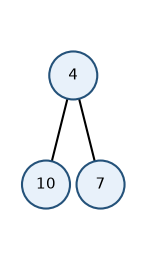

In [3]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)